In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import polars as pl
from sklearn.preprocessing import KBinsDiscretizer

# Cargar dataset original
df = pd.read_parquet("../data/dataset_5M.parquet")

# Estadísticas originales de la variable edad (usando desviación estándar poblacional ddof=0)
original = {
    "media": df["edad"].mean(),
    "desviacion": df["edad"].std(ddof=0),
    "minimo": df["edad"].min(),
    "maximo": df["edad"].max(),
    "p25": df["edad"].quantile(0.25),
    "p50": df["edad"].quantile(0.50),
    "p75": df["edad"].quantile(0.75)
}

df_original_stats = pd.DataFrame([original])
print("Estadísticas originales calculadas:")
df_original_stats

Estadísticas originales calculadas:


,media,desviacion,minimo,maximo,p25,p50,p75
0,39.997822,12.001378,-19.761751,100.405663,31.898256,40.000473,48.091603


In [2]:
# Cargar con Polars y castear a Float32
df_pl = pl.read_parquet("../data/dataset_5M.parquet")
df32 = df_pl.with_columns([
    pl.col("edad").cast(pl.Float32)
])

# Obtener estadísticas de la versión reducida
stats_float32 = df32.select([
    pl.col("edad").mean().alias("media"),
    pl.col("edad").std(ddof=0).alias("desviacion"),
    pl.col("edad").min().alias("minimo"),
    pl.col("edad").max().alias("maximo"),
    pl.col("edad").quantile(0.25).alias("p25"),
    pl.col("edad").quantile(0.50).alias("p50"),
    pl.col("edad").quantile(0.75).alias("p75")
]).row(0, named=True)

# Calcular error relativo porcentual
resultados_float32 = []
for metrica in ["media", "desviacion", "p25", "p50", "p75"]:
    valor_original = original[metrica]
    valor_reducido = stats_float32[metrica]
    error_relativo = (
        abs(valor_original - valor_reducido) / abs(valor_original) * 100
        if valor_original != 0 else np.nan
    )
    resultados_float32.append({
        "metrica": metrica,
        "original": valor_original,
        "float32": valor_reducido,
        "error_relativo_pct": error_relativo
    })

tabla_float32 = pd.DataFrame(resultados_float32)

# Guardar resultado
tabla_float32.to_csv("../resultados/tablas/fidelidad_float32.csv", index=False)
print("Tabla fidelidad_float32.csv guardada con éxito.")
tabla_float32

Tabla fidelidad_float32.csv guardada con éxito.


,metrica,original,float32,error_relativo_pct
0,media,39.997822,39.997822,4.726145e-07
1,desviacion,12.001378,12.001378,1.952317e-06
2,p25,31.898256,31.898262,2.029269e-05
3,p50,40.000473,40.000473,9.249729e-07
4,p75,48.091603,48.091602,6.472262e-07


In [3]:
X = df[["edad"]].to_numpy()
estrategias = ["uniform", "quantile", "kmeans"]
filas_fidelidad = []

for estrategia in estrategias:
    discretizador = KBinsDiscretizer(
        n_bins=10,
        encode="ordinal",
        strategy=estrategia,
        random_state=42
    )
    X_discreto = discretizador.fit_transform(X)
    X_reconstruido = discretizador.inverse_transform(X_discreto).ravel()
    
    media_reconstruida = X_reconstruido.mean()
    desviacion_reconstruida = X_reconstruido.std(ddof=0)
    
    error_media = abs(original["media"] - media_reconstruida) / abs(original["media"]) * 100
    error_desviacion = abs(original["desviacion"] - desviacion_reconstruida) / abs(original["desviacion"]) * 100
    
    filas_fidelidad.append({
        "estrategia": estrategia,
        "media_original": original["media"],
        "media_reconstruida": media_reconstruida,
        "error_media_pct": error_media,
        "desviacion_original": original["desviacion"],
        "desviacion_reconstruida": desviacion_reconstruida,
        "error_desviacion_pct": error_desviacion
    })

tabla_sklearn = pd.DataFrame(filas_fidelidad)

# Guardar tabla
tabla_sklearn.to_csv("../resultados/tablas/fidelidad_sklearn.csv", index=False)
print("Tabla fidelidad_sklearn.csv guardada con éxito.")
tabla_sklearn

Tabla fidelidad_sklearn.csv guardada con éxito.


,estrategia,media_original,media_reconstruida,error_media_pct,desviacion_original,desviacion_reconstruida,error_desviacion_pct
0,uniform,39.997822,39.997717,0.000261,12.001378,12.375034,3.113441
1,quantile,39.997822,40.459246,1.153623,12.001378,16.790248,39.902673
2,kmeans,39.997822,39.968176,0.074119,12.001378,13.182224,9.839256


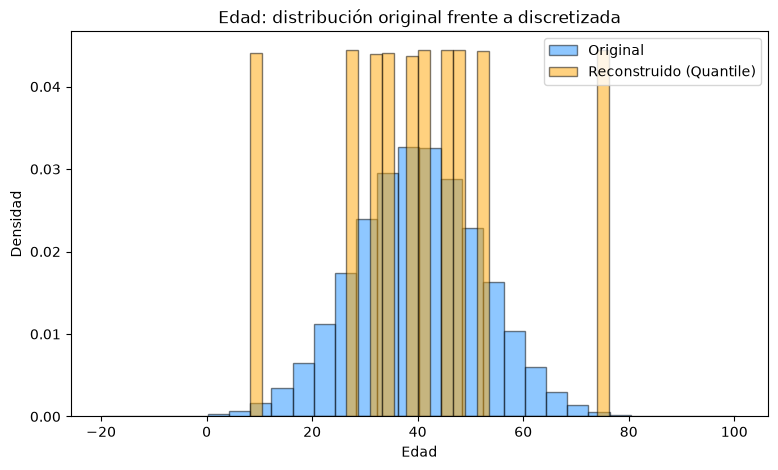

Gráfico comparacion_histograma_sklearn.png guardado.


In [4]:
discretizador = KBinsDiscretizer(
    n_bins=10,
    encode="ordinal",
    strategy="quantile",
    random_state=42
)
X_discreto = discretizador.fit_transform(df[["edad"]].to_numpy())
X_reconstruido = discretizador.inverse_transform(X_discreto).ravel()

plt.figure(figsize=(9, 5))
plt.hist(df["edad"], bins=30, density=True, alpha=0.5, label="Original", color="dodgerblue", edgecolor="black")
plt.hist(X_reconstruido, bins=30, density=True, alpha=0.5, label="Reconstruido (Quantile)", color="orange", edgecolor="black")

plt.title("Edad: distribución original frente a discretizada")
plt.xlabel("Edad")
plt.ylabel("Densidad")
plt.legend()

# Guardar gráfico
plt.savefig("../resultados/graficos/comparacion_histograma_sklearn.png", dpi=300, bbox_inches="tight")
plt.show()
print("Gráfico comparacion_histograma_sklearn.png guardado.")

In [6]:
import os

archivos = [
    "../resultados/tablas/fidelidad_float32.csv",
    "../resultados/tablas/fidelidad_sklearn.csv",
    "../resultados/graficos/comparacion_histograma_sklearn.png"
]

print("--- VERIFICACIÓN DE ARCHIVOS DE FIDELIDAD ---")
for f in archivos:
    print(f"{' Encontrado' if os.path.exists(f) else ' Falta'}: {f}")

--- VERIFICACIÓN DE ARCHIVOS DE FIDELIDAD ---
 Encontrado: ../resultados/tablas/fidelidad_float32.csv
 Encontrado: ../resultados/tablas/fidelidad_sklearn.csv
 Encontrado: ../resultados/graficos/comparacion_histograma_sklearn.png
